In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os.path as path

In [35]:
inDir = "L:\\stt"
session = "session003"

sessionDir = path.join(inDir,session)
if not path.exists(sessionDir):
    print(f"ERROR: path {sessionDir} not found")
else:
    print(f"reading input from {sessionDir}")

reading input from L:\stt\session003


In [36]:
box = pd.read_csv(path.join(sessionDir,"box-0.csv"))
box.head()

,ts-sys,ts-dev,T-0,P-0,out-0,T-1,P-1,out-1,T-2,P-2,out-2,T-3,P-3,out-3,T-4,P-4,out-4,T-5,P-5,out-5


In [37]:
myo = pd.read_csv(path.join(sessionDir,"myo.csv"))
myo.head()

,ts-sys,ts-dev,EMG-ch0,EMG-ch1,EMG-ch2,EMG-ch3,EMG-ch4,EMG-ch5,EMG-ch6,EMG-ch7
0,1.787654e+09,2595637.175,-0.640625,0.171875,-0.015625,-0.007812,-0.007812,-0.007812,-0.007812,0.007812
1,1.787654e+09,2595710.188,-0.109375,-0.101562,-0.148438,-0.023438,-0.015625,-0.023438,-0.015625,-0.085938
2,1.787654e+09,2595777.191,0.187500,0.289062,-0.031250,0.023438,0.007812,0.000000,0.000000,-0.046875
3,1.787654e+09,2595853.175,0.070312,0.015625,-0.062500,-0.007812,-0.015625,-0.015625,-0.023438,0.000000
4,1.787654e+09,2595914.176,-0.070312,-0.117188,0.007812,-0.007812,-0.007812,0.007812,0.000000,0.085938


In [38]:
ui = pd.read_csv(path.join(sessionDir,"ui.csv"))
ui.head()

,ts-sys,ts-dev,FSR-0,FSR-1,FSR-2,FSR-3,FSR-4,FSR-5,FSR-6,FSR-7,FSR-8,FSR-9,FSR-10,FSR-11
0,1.787654e+09,13108.777,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
1,1.787654e+09,13108.847,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2,1.787654e+09,13108.907,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
3,1.787654e+09,13108.967,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
4,1.787654e+09,13109.047,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [39]:
events = pd.read_csv(path.join(sessionDir,"log.csv"))
events.head()

,timestamp,datetime,device,event
0,1.787654e+09,2026-08-25 12:31:23.565297,A:0,start (A-0-2026-08-25 12-31-23.aac)
1,1.787654e+09,2026-08-25 12:31:23.581295,V:0,start (V-0-2026-08-25 12-31-23.mkv)
2,1.787654e+09,2026-08-25 12:31:23.596297,V:1,start (V-1-2026-08-25 12-31-23.mkv)
3,1.787654e+09,2026-08-25 12:31:23.618295,V:2,start (V-2-2026-08-25 12-31-23.mkv)
4,1.787654e+09,2026-08-25 12:31:23.655298,V:3,start (V-3-2026-08-25 12-31-23.mkv)


In [40]:
markers = events[events['device']=='marker']

split_paths = markers['event'].str.strip('/').str.split('/', expand=True)
markers['role'] = split_paths[0]    # 'user' or 'investigator'
markers['action'] = split_paths[1]  # 'pinch', 'tripod', 'power', 'relax'
markers['userID'] = split_paths[2]  # user 0, 1, 2

markers.head()

C:\Users\iko79\AppData\Local\Temp\ipykernel_27124\466625068.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  markers['role'] = split_paths[0]    # 'user' or 'investigator'
C:\Users\iko79\AppData\Local\Temp\ipykernel_27124\466625068.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  markers['action'] = split_paths[1]  # 'pinch', 'tripod', 'power', 'relax'
C:\Users\iko79\AppData\Local\Temp\ipykernel_27124\466625068.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a Data

,timestamp,datetime,device,event,role,action,userID
5,1.787654e+09,2026-08-25 12:31:32.567739,marker,/investigator/power/0,investigator,power,0
6,1.787654e+09,2026-08-25 12:31:33.359521,marker,/investigator/power/1,investigator,power,1
7,1.787654e+09,2026-08-25 12:31:34.012995,marker,/investigator/power/2,investigator,power,2
8,1.787654e+09,2026-08-25 12:31:40.658961,marker,/investigator/relax/0,investigator,relax,0
9,1.787654e+09,2026-08-25 12:31:43.015829,marker,/investigator/relax/1,investigator,relax,1


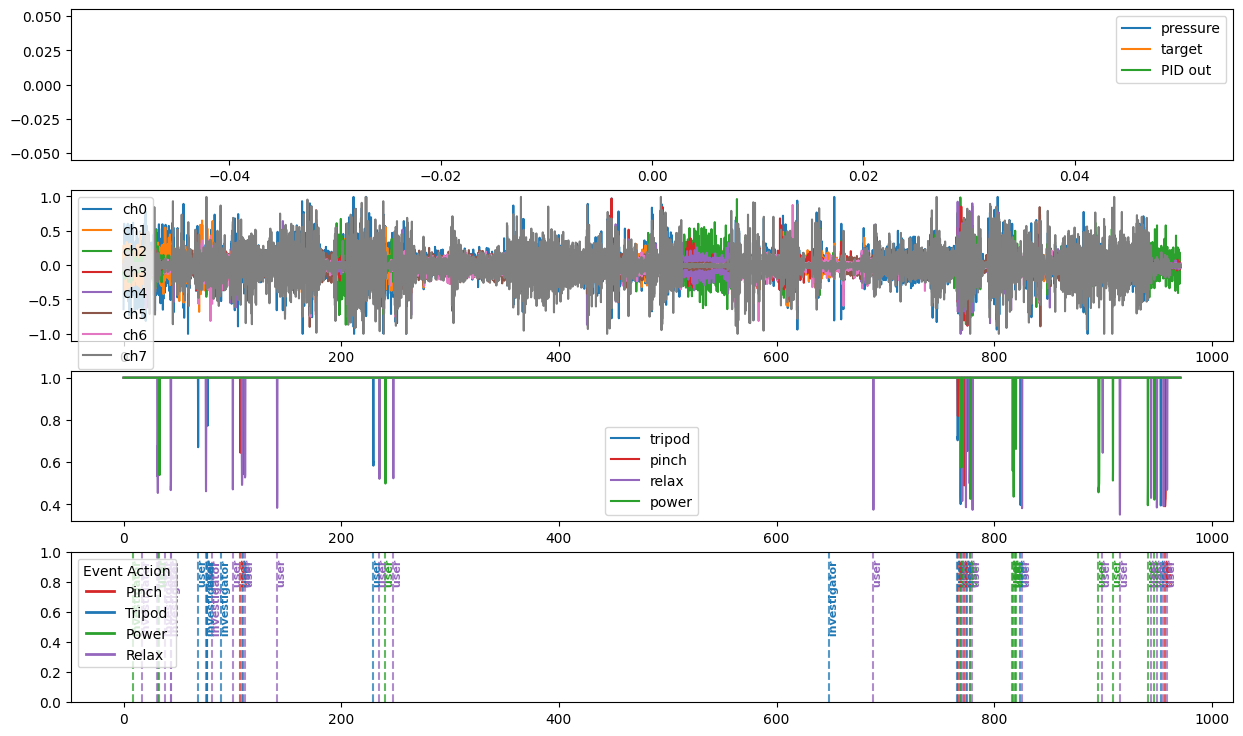

In [41]:
COLORS = [
    'tab:red',
    'tab:blue',
    'tab:green',
    'tab:purple'
]

t0 = ui['ts-sys'][0]

fig,axs=plt.subplots(4,1,figsize=(15,9))

ax = axs[0]

ax.plot(box['ts-sys'] - t0, box['P-0'], label='pressure')
ax.plot(box['ts-sys'] - t0, box['T-0'], label='target')
ax.plot(box['ts-sys'] - t0, box['out-0'], label='PID out')
ax.legend()

ax = axs[1]

for i in range(8):
    ax.plot(myo['ts-sys'] - t0, myo[f'EMG-ch{i}'], label=f'ch{i}')
ax.legend()

ax = axs[2]

labels = [
    'tripod',
    'pinch',
    'relax',
    'power',
]

COLOR_MAP = {
    'pinch': COLORS[0],
    'tripod': COLORS[1],
    'power': COLORS[2],
    'relax': COLORS[3]
}

#values 0-3 are buttons data of user #0
#values 4-7 are buttons data of user #1
#values 8-11 are buttons data of user #2
for i in range(4):
    ax.plot(ui['ts-sys'] - t0, ui[f'FSR-{i}'], label=labels[i],color=COLOR_MAP[labels[i]])
ax.legend()

ax = axs[3]

for _, row in markers.iterrows():

    # only draw user #0
    if row['userID'] != '0':
        continue

    color = COLOR_MAP.get(row['action'], 'gray')

    ax.axvline(x=row['timestamp']-t0, color=color, linestyle='--', alpha=0.75, linewidth=1.5)
    
    # Add text label at the top
    ax.text(
        x=row['timestamp']-t0,
        y=0.95,
        s=f" {row['role']}",
        rotation=90,
        color=color,
        verticalalignment='top',
        transform=ax.get_xaxis_transform(),
        fontsize=8,
        fontweight='bold'
    )

legend_handles = [
    plt.Line2D([0], [0], color=color, lw=2, label=action.capitalize())
    for action, color in COLOR_MAP.items()
]
ax.set_xlim(axs[1].get_xlim())
ax.legend(handles=legend_handles, title="Event Action", loc="upper left")